In [1]:
import pandas as pd

# 1. Listings
listings_df = pd.read_csv('../data/Listings .csv', encoding='latin1')

# 2. Listings Data Dictionary
listings_dict_df = pd.read_csv('../data/Listings_data_dictionary.csv', encoding='latin1')

# 3. Reviews
reviews_df = pd.read_csv('../data/Reviews.csv', encoding='latin1')

# 4. Reviews Data Dictionary
reviews_dict_df = pd.read_csv('../data/Reviews_data_dictionary.csv', encoding='latin1')


C:\Users\user\AppData\Local\Temp\ipykernel_17748\2142787199.py:4: DtypeWarning: Columns (5,13) have mixed types. Specify dtype option on import or set low_memory=False.
  listings_df = pd.read_csv('../data/Listings .csv', encoding='latin1')


In [2]:
listings_df.shape

(279712, 33)

In [3]:
reviews_df.shape

(5373143, 4)

In [4]:
listings_df.columns

Index(['listing_id', 'name', 'host_id', 'host_since', 'host_location',
       'host_response_time', 'host_response_rate', 'host_acceptance_rate',
       'host_is_superhost', 'host_total_listings_count',
       'host_has_profile_pic', 'host_identity_verified', 'neighbourhood',
       'district', 'city', 'latitude', 'longitude', 'property_type',
       'room_type', 'accommodates', 'bedrooms', 'amenities', 'price',
       'minimum_nights', 'maximum_nights', 'review_scores_rating',
       'review_scores_accuracy', 'review_scores_cleanliness',
       'review_scores_checkin', 'review_scores_communication',
       'review_scores_location', 'review_scores_value', 'instant_bookable'],
      dtype='object')

In [5]:
reviews_df.columns

Index(['listing_id', 'review_id', 'date', 'reviewer_id'], dtype='object')

In [6]:
import pandas as pd

listings_missing = pd.DataFrame({
    'Dtype': listings_df.dtypes,
    'Missing_Count': listings_df.isnull().sum(),
    'Missing_Percentage (%)': (listings_df.isnull().sum() / len(listings_df)) * 100
})

print("=== LISTINGS MISSING VALUES (Top 15) ===")
print(listings_missing[listings_missing['Missing_Count'] > 0].sort_values(by='Missing_Percentage (%)', ascending=False).head(15))

print("\n=== REVIEWS MISSING VALUES ===")
print(reviews_df.isnull().sum())

=== LISTINGS MISSING VALUES (Top 15) ===
                               Dtype  Missing_Count  Missing_Percentage (%)
district                      object         242700               86.767818
host_response_time            object         128782               46.040928
host_response_rate           float64         128782               46.040928
host_acceptance_rate         float64         113087               40.429799
review_scores_value          float64          91785               32.814109
review_scores_location       float64          91775               32.810534
review_scores_checkin        float64          91771               32.809104
review_scores_accuracy       float64          91713               32.788368
review_scores_communication  float64          91687               32.779073
review_scores_cleanliness    float64          91665               32.771208
review_scores_rating         float64          91405               32.678255
bedrooms                     float64          2

In [7]:
print("=== PRICE STATS ===")
print(listings_df['price'].describe())

print("\nZero or Negative prices count:", (listings_df['price'] <= 0).sum())

print("Missing prices count:", listings_df['price'].isnull().sum())

=== PRICE STATS ===
count    279712.000000
mean        608.792737
std        3441.826611
min           0.000000
25%          75.000000
50%         150.000000
75%         474.000000
max      625216.000000
Name: price, dtype: float64

Zero or Negative prices count: 113
Missing prices count: 0


In [8]:
zero_prices = listings_df[listings_df['price'] <= 0][['listing_id', 'name', 'price']]
print("=== ROWS WITH ZERO OR NEGATIVE PRICES (FIRST 5) ===")
print(zero_prices.head())

max_price_row = listings_df[listings_df['price'] == listings_df['price'].max()][['listing_id', 'name', 'price']]
print("\n=== ROW WITH THE HIGHEST PRICE (MAX) ===")
print(max_price_row)

print("\n=== TOP 5 MOST EXPENSIVE HOUSES ===")
print(listings_df[['listing_id', 'name', 'price']].sort_values(by='price', ascending=False).head(5))

=== ROWS WITH ZERO OR NEGATIVE PRICES (FIRST 5) ===
        listing_id                                         name  price
98209     44312919  Bienvenue ÃÂ  l'HÃÂ´tel des 3 CollÃÂ¨ges      0
202022    42830099                                   Hotel Hugo      0
202023    43247472                                     Hotel 57      0
203253    43205598                             Wellington Hotel      0
203254    44567521                   The Standard, East Village      0

=== ROW WITH THE HIGHEST PRICE (MAX) ===
        listing_id                                  name   price
181027    13879989  Temporary rentals for Brazilian Cup.  625216

=== TOP 5 MOST EXPENSIVE HOUSES ===
        listing_id                                     name   price
181027    13879989     Temporary rentals for Brazilian Cup.  625216
162251    47885441          Hotel Boutique Maison Salamanca  499000
98808     23895520  Habitacion a 40min del centro historico  350000
135705     3410763      Amazing view and 

In [9]:
import numpy as np

listings_clean = listings_df[listings_df['price'] > 0].copy()

listings_clean['log_price'] = np.log1p(listings_clean['price'])

print("=== PRICE QUANTILES ===")
print(listings_clean['price'].quantile([0.01, 0.50, 0.95, 0.99]))

=== PRICE QUANTILES ===
0.01      25.0
0.50     150.0
0.95    2000.0
0.99    6500.0
Name: price, dtype: float64


In [10]:
print("=== ROOM TYPES ===")
print(listings_clean['room_type'].value_counts())

print("\n=== ACCOMMODATES & BEDROOMS STATS ===")
print(listings_clean[['accommodates', 'bedrooms']].describe())

print("\nMissing bedrooms count:", listings_clean['bedrooms'].isnull().sum())

=== ROOM TYPES ===
room_type
Entire place    182005
Private room     86988
Hotel room        5744
Shared room       4862
Name: count, dtype: int64

=== ACCOMMODATES & BEDROOMS STATS ===
        accommodates       bedrooms
count  279599.000000  250277.000000
mean        3.289733       1.515509
std         2.133007       1.153080
min         1.000000       1.000000
25%         2.000000       1.000000
50%         2.000000       1.000000
75%         4.000000       2.000000
max        16.000000      50.000000

Missing bedrooms count: 29322


In [11]:
unique_users = reviews_df['reviewer_id'].nunique()
unique_listings_rev = reviews_df['listing_id'].nunique()

print(f"Unique Users (Reviewers): {unique_users}")
print(f"Unique Houses in Reviews: {unique_listings_rev}")

user_counts = reviews_df.groupby('reviewer_id').size()

print("\n=== USER ACTIVITY STATS ===")
print(user_counts.describe())

more_than_one = (user_counts > 1).sum()
print(f"\nUsers Who Have Submitted More Than One Review: {more_than_one} ({more_than_one / unique_users * 100:.2f}%)")

Unique Users (Reviewers): 4450005
Unique Houses in Reviews: 193556

=== USER ACTIVITY STATS ===
count    4.450005e+06
mean     1.207447e+00
std      7.535784e-01
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      2.830000e+02
dtype: float64

Users Who Have Submitted More Than One Review: 611285 (13.74%)


In [12]:
listings_ids = set(listings_clean['listing_id'])
reviewed_ids = set(reviews_df['listing_id'])

has_reviews = listings_ids.intersection(reviewed_ids)
no_reviews = listings_ids - reviewed_ids

print(f"Total Cleaned Listings: {len(listings_ids)}")
print(f"Listings with Reviews: {len(has_reviews)} ({len(has_reviews)/len(listings_ids)*100:.2f}%)")
print(f"Listings Without Reviews (Cold Listings): {len(no_reviews)} ({len(no_reviews)/len(listings_ids)*100:.2f}%)")

Total Cleaned Listings: 279599
Listings with Reviews: 193556 (69.23%)
Listings Without Reviews (Cold Listings): 86043 (30.77%)


In [13]:
import ast
from collections import Counter

print("=== AMENITIES SAMPLE ===")
print(listings_clean['amenities'].head(3))

all_amenities = []

for item in listings_clean['amenities'].dropna():
    try:
        parsed = ast.literal_eval(item)
        if isinstance(parsed, list):
            all_amenities.extend(parsed)
    except:
        all_amenities.extend([x.strip('[]"{}\' ') for x in item.split(',')])

amenity_counts = Counter(all_amenities)
print("\n=== TOP 10 AMENITIES ===")
for amenity, count in amenity_counts.most_common(10):
    print(f"{amenity}: {count}")

=== AMENITIES SAMPLE ===
0    ["Heating", "Kitchen", "Washer", "Wifi", "Long...
1    ["Shampoo", "Heating", "Kitchen", "Essentials"...
2    ["Heating", "TV", "Kitchen", "Washer", "Wifi",...
Name: amenities, dtype: object

=== TOP 10 AMENITIES ===
Wifi: 260090
Essentials: 253532
Long term stays allowed: 240941
Kitchen: 240915
TV: 212972
Hangers: 211251
Hair dryer: 188631
Iron: 187706
Washer: 185072
Heating: 184249


C:\Users\user\AppData\Local\Temp\ipykernel_17748\988532091.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(top_10_amenities.values()), y=list(top_10_amenities.keys()), ax=axes[1, 0], palette='viridis')


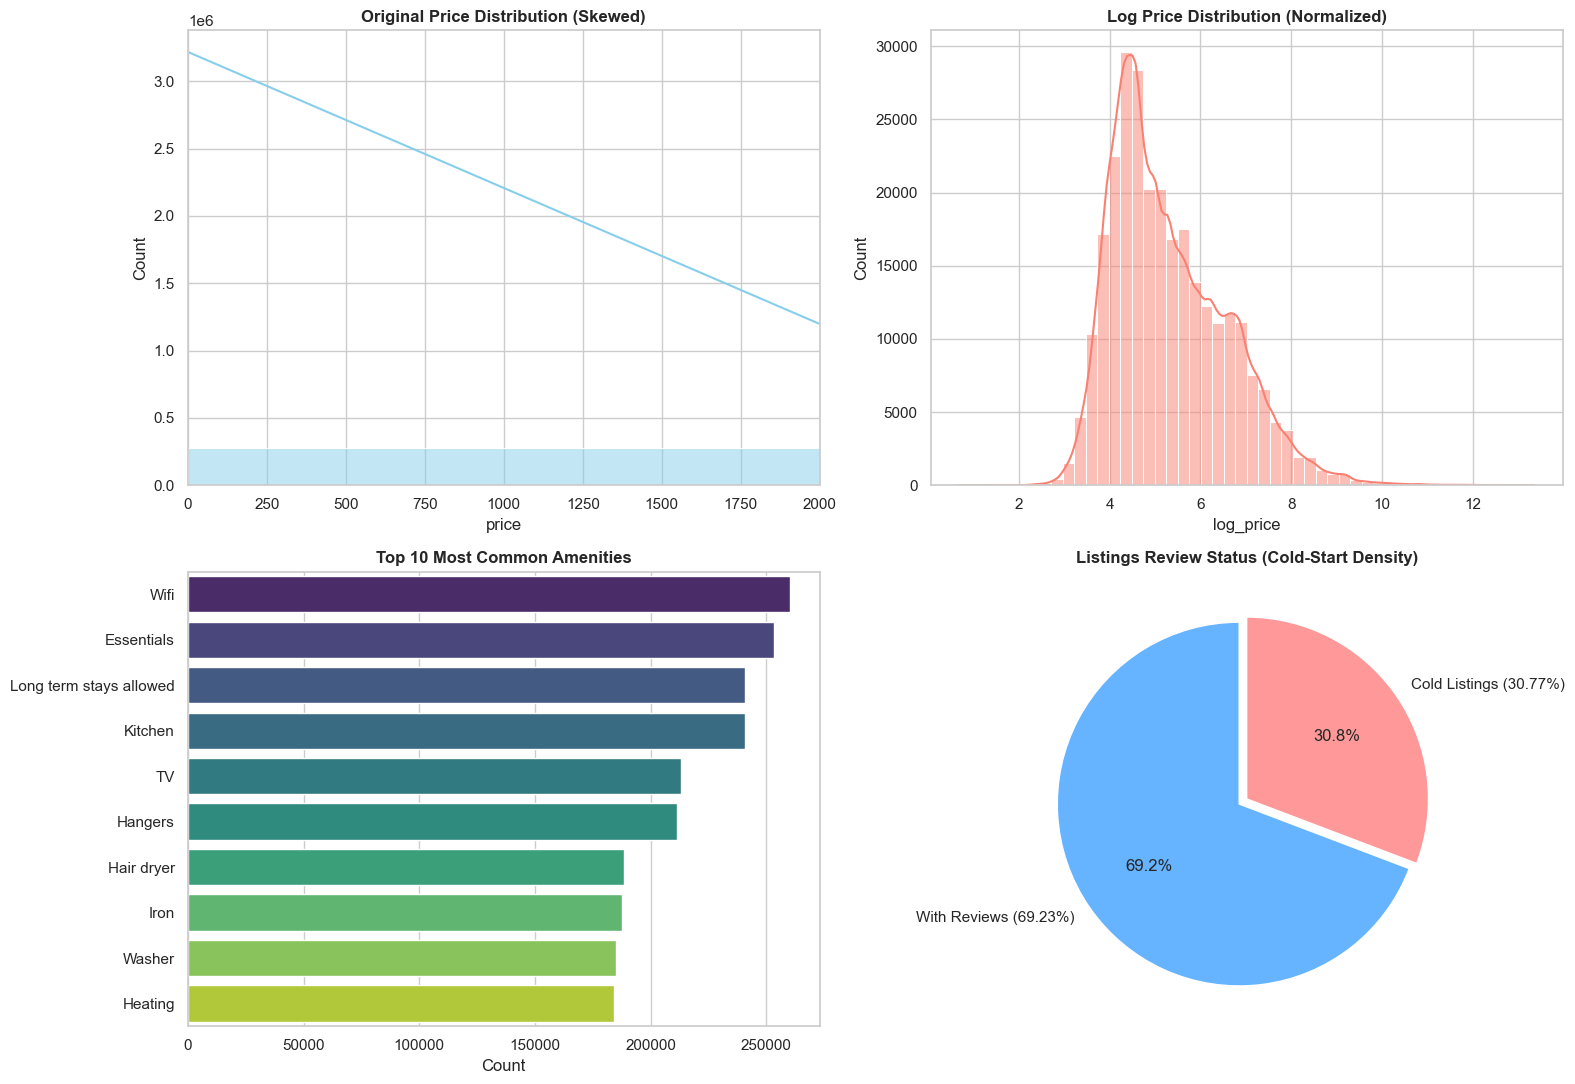

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

sns.histplot(listings_clean['price'], bins=50, ax=axes[0, 0], color='skyblue', kde=True)
axes[0, 0].set_title('Original Price Distribution (Skewed)', fontsize=12, fontweight='bold')
axes[0, 0].set_xlim(0, 2000)

sns.histplot(listings_clean['log_price'], bins=50, ax=axes[0, 1], color='salmon', kde=True)
axes[0, 1].set_title('Log Price Distribution (Normalized)', fontsize=12, fontweight='bold')

top_10_amenities = dict(amenity_counts.most_common(10))
sns.barplot(x=list(top_10_amenities.values()), y=list(top_10_amenities.keys()), ax=axes[1, 0], palette='viridis')
axes[1, 0].set_title('Top 10 Most Common Amenities', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Count')

review_status = ['With Reviews (69.23%)', 'Cold Listings (30.77%)']
counts = [len(has_reviews), len(no_reviews)]
axes[1, 1].pie(counts, labels=review_status, autopct='%1.1f%%', colors=['#66b3ff','#ff9999'], startangle=90, explode=(0.05, 0))
axes[1, 1].set_title('Listings Review Status (Cold-Start Density)', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

Feature Engineering

լրացրել եմ bedrooms-ի բացակայող արժեքները (NaN)՝ հիմնվելով accommodates-ի մեդիան արժեքների վրա: Այնուհետև amenities տեքստային սյունակը փոխարինել եմ Python-ի ցուցակների, առանձնացրել ամենահաճախ հանդիպող TOP 30 հարմարությունները և ֆիլտրել դրանք: Վերջում MultiLabelBinarizer-ի միջոցով կատարել եմ One-Hot Encoding՝ TOP 30 հարմարությունները դարձնելով առանձին binary (0/1) սյունակներով աղյուսակ:

In [15]:
import ast
from collections import Counter
from sklearn.preprocessing import MultiLabelBinarizer

bedroom_medians = listings_clean.groupby('accommodates')['bedrooms'].transform('median')
listings_clean['bedrooms'] = listings_clean['bedrooms'].fillna(bedroom_medians)
listings_clean['bedrooms'] = listings_clean['bedrooms'].fillna(listings_clean['bedrooms'].median())

print("Bedrooms NaNs count after imputation:", listings_clean['bedrooms'].isnull().sum())

def parse_amenities(x):
    if pd.isna(x):
        return []
    try:
        parsed = ast.literal_eval(x)
        if isinstance(parsed, list):
            return [i.strip('[]"{}\' ') for i in parsed]
        return []   
    except Exception:
        return [i.strip('[]"{}\' ') for i in str(x).split(',')]

listings_clean['amenities_list'] = listings_clean['amenities'].apply(parse_amenities)

all_amenities_flat = [item for sublist in listings_clean['amenities_list'] for item in sublist]
top_30_amenities = [item[0] for item in Counter(all_amenities_flat).most_common(30)]

listings_clean['filtered_amenities'] = listings_clean['amenities_list'].apply(
    lambda x: [item for item in x if item in top_30_amenities]
)

mlb = MultiLabelBinarizer()
amenities_encoded = pd.DataFrame(
    mlb.fit_transform(listings_clean['filtered_amenities']),
    columns=mlb.classes_,
    index=listings_clean.index
)

print(f"\nAmenities Encoded Shape: {amenities_encoded.shape}")
print("\nSample One-Hot Encoded Amenities:")
print(amenities_encoded.head())

Bedrooms NaNs count after imputation: 0

Amenities Encoded Shape: (279599, 30)

Sample One-Hot Encoded Amenities:
   Air conditioning  Bed linens  Carbon monoxide alarm  Coffee maker  \
0                 0           0                      0             0   
1                 0           0                      0             0   
2                 0           0                      0             0   
3                 0           0                      0             0   
4                 0           0                      0             0   

   Cooking basics  Dedicated workspace  Dishes and silverware  Dryer  \
0               0                    0                      0      0   
1               0                    0                      0      1   
2               0                    0                      0      0   
3               0                    0                      0      0   
4               0                    0                      0      1   

   Elevator  Essenti

Իրականացրել եմ մոդելի համար Item Feature Matrix-ի հավաքագրումը։

- `room_type`-ը կոդավորել եմ One-Hot Encoding-ով։
- Թվային ֆեչերները (`log_price`, `accommodates`, `bedrooms`) ստանդարտացրել եմ **ըստ քաղաքի**, քանի որ գները տարբեր արժույթներով են։
- `review_scores_rating`-ը միտումնավոր չեմ ներառել, որպեսզի cold-start տները (առանց review) չկողմնակալվեն։
- Միավորել եմ թվային ֆեչերները, room_type-ը և 30 amenities-ը՝ 36 չափանի մատրից։ Neighbourhood-ի 20 սյունակը ավելացնելուց հետո՝ 56 չափանի։

In [16]:
import numpy as np

room_type_encoded = pd.get_dummies(listings_clean['room_type'], prefix='room', drop_first=True)

num_cols = ['log_price', 'accommodates', 'bedrooms']
grp = listings_clean.groupby('city')[num_cols]
scaled_num_features = (
    (listings_clean[num_cols] - grp.transform('mean')) / (grp.transform('std') + 1e-9)
).fillna(0)

item_features = pd.concat([scaled_num_features, room_type_encoded, amenities_encoded], axis=1)

print("=== FEATURE ENGINEERING COMPLETED ===")
print(f"Final Item Features Matrix Shape: {item_features.shape}")  
print(item_features.head())

=== FEATURE ENGINEERING COMPLETED ===
Final Item Features Matrix Shape: (279599, 36)
   log_price  accommodates  bedrooms  room_Hotel room  room_Private room  \
0  -0.774810     -0.655672 -0.357385            False              False   
1   0.522869     -0.655672 -0.357385            False              False   
2   0.046809     -0.655672 -0.357385            False              False   
3  -0.632379     -0.655672 -0.357385            False              False   
4  -0.578760     -0.655672 -0.357385            False              False   

   room_Shared room  Air conditioning  Bed linens  Carbon monoxide alarm  \
0             False                 0           0                      0   
1             False                 0           0                      0   
2             False                 0           0                      0   
3             False                 0           0                      0   
4             False                 0           0                      0   

 

In [17]:

top_20_neighbourhoods = listings_clean['neighbourhood'].value_counts().head(20).index

neighbourhood_filtered = listings_clean['neighbourhood'].apply(
    lambda x: x if x in top_20_neighbourhoods else 'Other'
)

neighbourhood_encoded = pd.get_dummies(neighbourhood_filtered, prefix='neigh', drop_first=True)

item_features_with_geo = pd.concat([item_features, neighbourhood_encoded], axis=1)

print("=== NEIGHBOURHOOD ADDED ===")
print(f"Updated Item Features Matrix Shape: {item_features_with_geo.shape}")

=== NEIGHBOURHOOD ADDED ===
Updated Item Features Matrix Shape: (279599, 56)


In [18]:
import os

review_counts = reviews_df.groupby('listing_id').size()
listings_clean['number_of_reviews'] = (
    listings_clean['listing_id'].map(review_counts).fillna(0).astype(int)
)
print("Cold listings (0 reviews):", (listings_clean['number_of_reviews'] == 0).sum())  

os.makedirs('../data/processed', exist_ok=True)

item_features_with_geo.to_pickle('../data/processed/item_features.pkl')
listings_clean.to_pickle('../data/processed/listings_clean.pkl')

print(item_features_with_geo.shape)  
print("Data successfully saved into data/processed/ folder!")

Cold listings (0 reviews): 86043
(279599, 56)
Data successfully saved into data/processed/ folder!
